In [19]:
import pandas as pd
import numpy as np
from apyori import apriori

### Importing file

In [20]:
execfile = pd.read_excel("D:\\Data science\\Assignments\\Questions\\Association Rules\\Association Rules\\Online retail.xlsx", header=None)
execfile

,0
0,"shrimp,almonds,avocado,vegetables mix,green gr..."
1,"burgers,meatballs,eggs"
2,chutney
3,"turkey,avocado"
4,"mineral water,milk,energy bar,whole wheat rice..."
...,...
7496,"butter,light mayo,fresh bread"
7497,"burgers,frozen vegetables,eggs,french fries,ma..."
7498,chicken
7499,"escalope,green tea"


In [21]:
transactions = []
for index, row in execfile.iterrows():
    transaction = str(row[0]).split(',')
    transactions.append(transaction)

display(transactions[:5])

[['shrimp',
  'almonds',
  'avocado',
  'vegetables mix',
  'green grapes',
  'whole weat flour',
  'yams',
  'cottage cheese',
  'energy drink',
  'tomato juice',
  'low fat yogurt',
  'green tea',
  'honey',
  'salad',
  'mineral water',
  'salmon',
  'antioxydant juice',
  'frozen smoothie',
  'spinach',
  'olive oil'],
 ['burgers', 'meatballs', 'eggs'],
 ['chutney'],
 ['turkey', 'avocado'],
 ['mineral water', 'milk', 'energy bar', 'whole wheat rice', 'green tea']]

In [22]:
pd.DataFrame(transactions).to_csv("D:\\Data science\\Assignments\\Questions\\Association Rules\\Association Rules\\Online retail.csv", index=False, header=False)

In [23]:
df = pd.read_csv("D:\\Data science\\Assignments\\Questions\\Association Rules\\Association Rules\\Online retail.csv", header=None)
df

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
0,shrimp,almonds,avocado,vegetables mix,green grapes,whole weat flour,yams,cottage cheese,energy drink,tomato juice,low fat yogurt,green tea,honey,salad,mineral water,salmon,antioxydant juice,frozen smoothie,spinach,olive oil
1,burgers,meatballs,eggs,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,chutney,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,turkey,avocado,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,mineral water,milk,energy bar,whole wheat rice,green tea,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7496,butter,light mayo,fresh bread,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7497,burgers,frozen vegetables,eggs,french fries,magazines,green tea,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7498,chicken,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7499,escalope,green tea,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### converting to list

In [24]:
trans = []
for i in range(0, 7501):
    trans.append([str(df.values[i, j]) for j in range(0, 20)])

trans[0]

['shrimp',
 'almonds',
 'avocado',
 'vegetables mix',
 'green grapes',
 'whole weat flour',
 'yams',
 'cottage cheese',
 'energy drink',
 'tomato juice',
 'low fat yogurt',
 'green tea',
 'honey',
 'salad',
 'mineral water',
 'salmon',
 'antioxydant juice',
 'frozen smoothie',
 'spinach',
 'olive oil']

### using apriori for association rules

In [26]:
results = apriori(transactions=trans, min_support=0.003, min_confidence=0.2, min_lift=3, min_length=2, max_length=2)
reports = list(results)
dr = pd.DataFrame(reports)
dr

,items,support,ordered_statistics
0,"(chicken, light cream)",0.004533,"[((light cream), (chicken), 0.2905982905982905..."
1,"(mushroom cream sauce, escalope)",0.005733,"[((mushroom cream sauce), (escalope), 0.300699..."
2,"(pasta, escalope)",0.005866,"[((pasta), (escalope), 0.3728813559322034, 4.7..."
3,"(fromage blanc, honey)",0.003333,"[((fromage blanc), (honey), 0.2450980392156863..."
4,"(ground beef, herb & pepper)",0.015998,"[((herb & pepper), (ground beef), 0.3234501347..."
5,"(ground beef, tomato sauce)",0.005333,"[((tomato sauce), (ground beef), 0.37735849056..."
6,"(olive oil, light cream)",0.003200,"[((light cream), (olive oil), 0.20512820512820..."
7,"(olive oil, whole wheat pasta)",0.007999,"[((whole wheat pasta), (olive oil), 0.27149321..."
8,"(pasta, shrimp)",0.005066,"[((pasta), (shrimp), 0.3220338983050847, 4.506..."


In [28]:
base= []
add= []
support= []
confidance= []
lift= []

for i in range(0,len(reports)):
    base.append(reports[i][2][0][0]) # baseitem
    add.append(reports[i][2][0][1]) # additem
    support.append(reports[i][1]) # support
    confidance.append(reports[i][2][0][2]) # cofidance
    lift.append(reports[i][2][0][3]) # lift

Base = pd.DataFrame(base)
add = pd.DataFrame(add)
spt = pd.DataFrame(support)
con = pd.DataFrame(confidance)
lift = pd.DataFrame(lift)

df_new = pd.concat([Base,add,spt,con,lift], axis=1)
df_new.columns = ['base', 'add', 'support', 'confidance', 'lift']
df_new

,base,add,support,confidance,lift
0,light cream,chicken,0.004533,0.290598,4.843951
1,mushroom cream sauce,escalope,0.005733,0.300699,3.790833
2,pasta,escalope,0.005866,0.372881,4.700812
3,fromage blanc,honey,0.003333,0.245098,5.164271
4,herb & pepper,ground beef,0.015998,0.323450,3.291994
5,tomato sauce,ground beef,0.005333,0.377358,3.840659
6,light cream,olive oil,0.003200,0.205128,3.114710
7,whole wheat pasta,olive oil,0.007999,0.271493,4.122410
8,pasta,shrimp,0.005066,0.322034,4.506672


### Visulizing the confidance vs support with lift

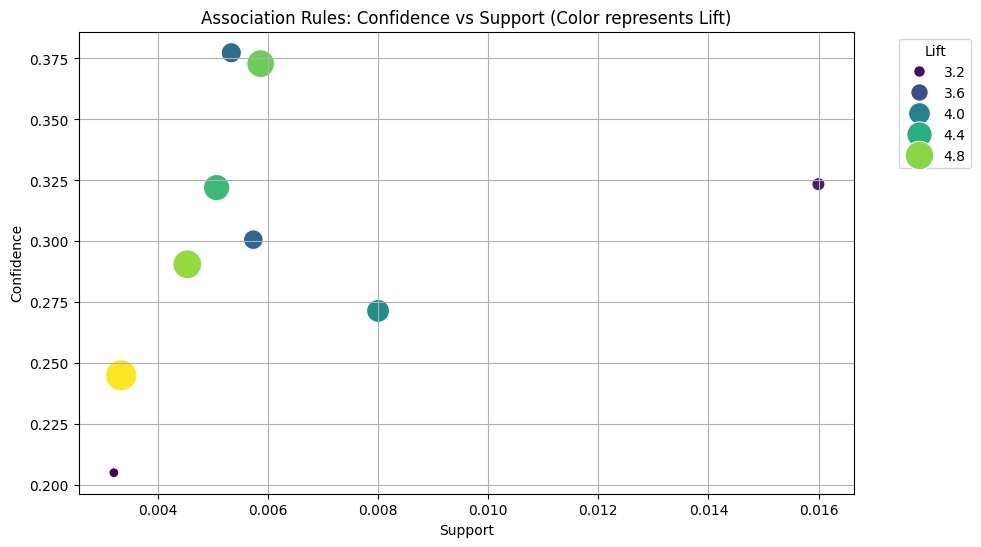

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a scatter plot of confidence vs support, with lift as color
plt.figure(figsize=(10, 6))
sns.scatterplot(x="support", y="confidance", hue="lift", size="lift", data=df_new, palette="viridis", sizes=(50, 500))
plt.title("Association Rules: Confidence vs Support (Color represents Lift)")
plt.xlabel("Support")
plt.ylabel("Confidence")
plt.legend(title="Lift", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.show()

we can see that with confidance nearly 0.375 and support of nearly 0.006 we are getting LIFT - 4.8  

so people prefer escalope while buying pasta  
aslo while buying fromage blanc they prefer honey

### Interview Questions

1.  **What is lift and why is it important in Association rules?**
    *   Lift is a metric that measures the strength of the association between two items in a rule, relative to their individual frequencies. It tells us how much more likely the consequent is to be purchased when the antecedent is purchased, compared to when the antecedent is not purchased. Lift is important because it helps to filter out rules that may have high confidence simply because the antecedent and consequent are popular items. A high lift value indicates a truly interesting and potentially actionable association.

2.  **What is support and Confidence. How do you calculate them?**
    *   **Support:** Support of an itemset is calculated as the number of transactions containing the itemset divided by the total number of transactions.
    *   **Confidence:** Confidence of a rule A -> B is calculated as the number of transactions containing both A and B divided by the number of transactions containing A.

3.  **What are some limitations or challenges of Association rules mining?**
    *   **Scalability:** Mining association rules from large datasets can be computationally expensive.
    *   **Spurious rules:** Generating a large number of rules, many of which may not be truly interesting or actionable.
    *   **Handling continuous data:** Association rule mining is primarily designed for categorical data, and handling continuous data requires discretization.
    *   **Interpreting complex rules:** Rules with many items can be difficult to interpret and understand.
    *   **Choosing appropriate thresholds:** Selecting the right values for minimum support, confidence, and lift can be challenging and may require trial and error.